In [28]:
import numpy as np

def fbm(hurst, timeseries_len):
        """
        Generate fractional Brownian motion (fBm) time series.

        This method uses the spectral synthesis method to generate a fBm time series
        with a specified Hurst exponent.

        Parameters:
        -----------
        hurst : float
            The Hurst exponent, a value between 0 and 1 that characterizes
            the fractal properties of the time series.

        Returns:
        --------
        numpy.ndarray
            A 1D array representing the generated fBm time series.

        Notes:
        ------
        - The length of the generated time series is determined by self.timeseries_len.
        - This method uses the Fourier filtering method to generate fBm.
        - The first frequency component is set to a small non-zero value (1e-6) to avoid division by zero.
        """

        n = timeseries_len
        f = np.fft.fftfreq(n)
        f[0] = 1e-6  # avoid division by zero
        psd = np.abs(f) ** (-2 * hurst - 1)
        gaussian = np.random.randn(n) + 1j * np.random.randn(n)
        fBm = np.fft.ifft(gaussian * np.sqrt(psd)).real
        return fBm

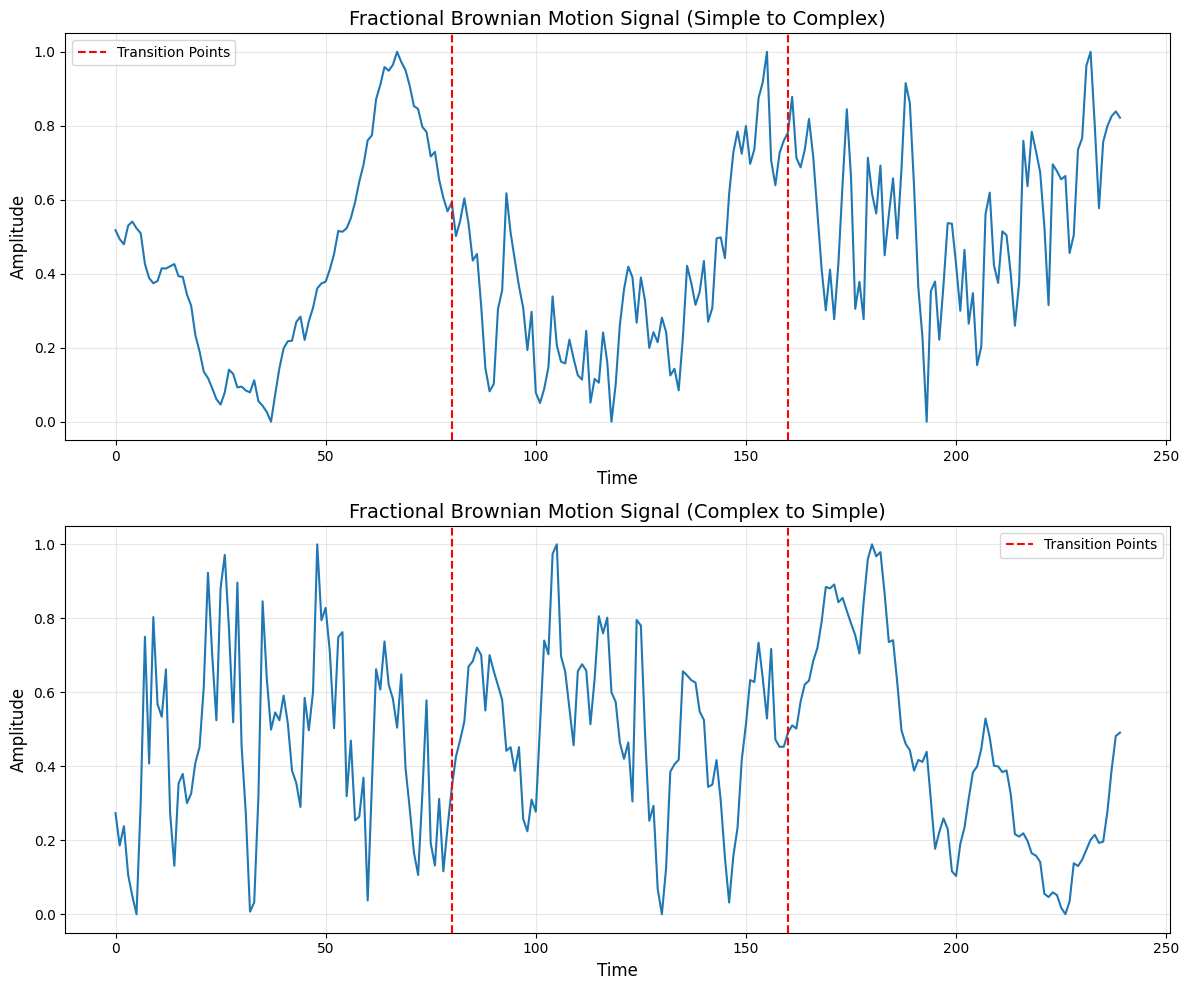

In [29]:
norm = lambda x: (x - np.min(x)) / (np.max(x) - np.min(x))

signal_s2c = np.concatenate([norm(fbm(0.8, 80)), norm(fbm(0.4, 80)), norm(fbm(0.1, 80))])
signal_c2s = np.concatenate([norm(fbm(0.1, 80)), norm(fbm(0.4, 80)), norm(fbm(0.8, 80))])

import matplotlib.pyplot as plt

# Create a figure with two subplots
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10))

# Plot the first signal (simple to complex)
ax1.plot(signal_s2c)
ax1.set_title("Fractional Brownian Motion Signal (Simple to Complex)", fontsize=14)
ax1.set_xlabel("Time", fontsize=12)
ax1.set_ylabel("Amplitude", fontsize=12)
ax1.grid(True, alpha=0.3)

# Add vertical lines to show the transition points for first signal
ax1.axvline(x=80, color="r", linestyle="--", label="Transition Points")
ax1.axvline(x=160, color="r", linestyle="--")
ax1.legend()

# Plot the second signal (complex to simple)
ax2.plot(signal_c2s)
ax2.set_title("Fractional Brownian Motion Signal (Complex to Simple)", fontsize=14)
ax2.set_xlabel("Time", fontsize=12)
ax2.set_ylabel("Amplitude", fontsize=12)
ax2.grid(True, alpha=0.3)

# Add vertical lines to show the transition points for second signal
ax2.axvline(x=80, color="r", linestyle="--", label="Transition Points")
ax2.axvline(x=160, color="r", linestyle="--")
ax2.legend()

plt.tight_layout()
plt.show()

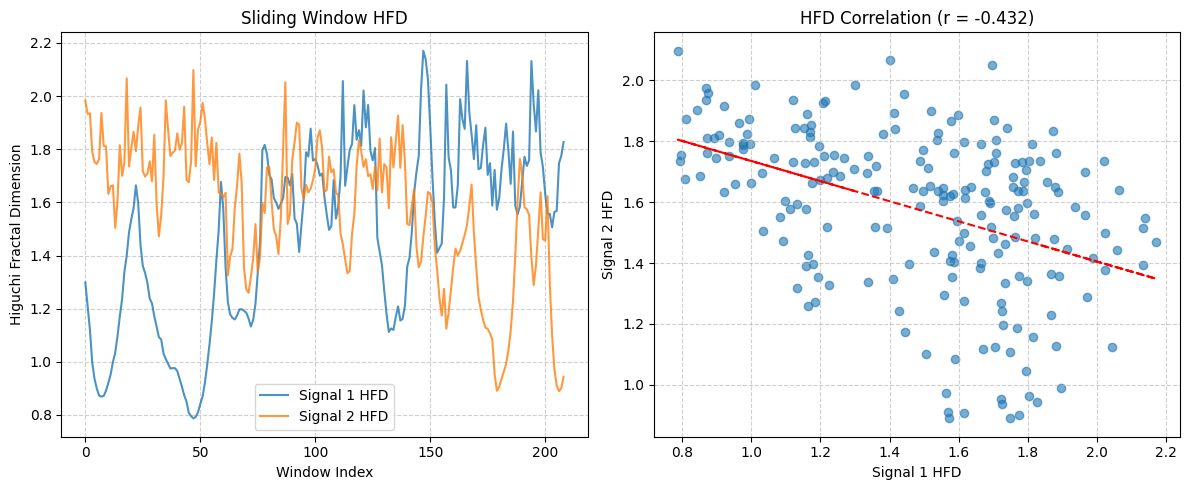

>>> complexity sequence length 209


(array([1.29899343, 1.21223629, 1.12161947, 0.99761907, 0.93641056,
        0.89922851, 0.87289212, 0.86911003, 0.87191772, 0.89131254,
        0.92038209, 0.95188629, 0.99920574, 1.03418836, 1.09685715,
        1.17109085, 1.23750075, 1.33869228, 1.39974257, 1.48696546,
        1.53671847, 1.57841587, 1.66415569, 1.596991  , 1.44025089,
        1.36071822, 1.33416814, 1.29751917, 1.23811513, 1.22005434,
        1.17138986, 1.13304402, 1.09258407, 1.08414198, 1.03156962,
        1.01060412, 0.99252406, 0.97493881, 0.97664308, 0.9760531 ,
        0.96562718, 0.93563335, 0.90743205, 0.8743001 , 0.85045626,
        0.80840112, 0.7956166 , 0.78740665, 0.79258286, 0.81001379,
        0.84147332, 0.86928284, 0.92066225, 0.98836634, 1.06506961,
        1.15220772, 1.25588776, 1.38236365, 1.49594367, 1.67739268,
        1.57448984, 1.35571208, 1.22448387, 1.17867365, 1.16522404,
        1.15955813, 1.1742479 , 1.19698221, 1.1982333 , 1.19221956,
        1.18489551, 1.16314764, 1.13302298, 1.15

In [ ]:
from complexeva.sequence import hfd

import numpy as np
from numpy.lib.stride_tricks import sliding_window_view
import matplotlib.pyplot as plt
from complexeva.sequence.higuchi import hfd

def sliding_window_complex_correlation(signal_1, signal_2, window_size=32, k_max=None):
    """
    Calculates and plots the sliding window Higuchi Fractal Dimension (HFD) 
    for two signals and their correlation.

    Args:
        signal_1 (np.ndarray): The first 1D signal.
        signal_2 (np.ndarray): The second 1D signal.
        window_size (int): The size of the sliding window. 
                           Note: A window size of 32 might be too small for 
                           stable HFD calculation, consider 100 or more.
        k_max (int, optional): The maximum k value for HFD calculation. 
                               Defaults to min(16, window_size // 2) if None.
    """
    if not isinstance(signal_1, np.ndarray):
        signal_1 = np.asarray(signal_1)
    if not isinstance(signal_2, np.ndarray):
        signal_2 = np.asarray(signal_2)

    if signal_1.ndim != 1 or signal_2.ndim != 1:
        raise ValueError("Input signals must be 1-dimensional.")
        
    min_len = min(len(signal_1), len(signal_2))
    if min_len < window_size:
        raise ValueError(f"Signal length ({min_len}) must be >= window_size ({window_size})")

    # Adjust signals to the same length
    signal_1 = signal_1[:min_len]
    signal_2 = signal_2[:min_len]

    # Determine k_max for HFD
    if k_max is None:
        k_max_hfd = min(16, window_size // 2) 
    else:
        k_max_hfd = k_max
        
    if k_max_hfd < 2:
        raise ValueError(f"k_max ({k_max_hfd}) must be at least 2. Increase window_size.")

    # Create sliding windows
    windows_1 = sliding_window_view(signal_1, window_shape=window_size)
    windows_2 = sliding_window_view(signal_2, window_shape=window_size)

    # Calculate HFD for each window
    hfd_1 = np.array([hfd(window, k_max=k_max_hfd) for window in windows_1])
    hfd_2 = np.array([hfd(window, k_max=k_max_hfd) for window in windows_2])

    # --- Plotting ---
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # Plot HFD sequences
    time_indices = np.arange(len(hfd_1))
    axes[0].plot(time_indices, hfd_1, label='Signal 1 HFD', alpha=0.8)
    axes[0].plot(time_indices, hfd_2, label='Signal 2 HFD', alpha=0.8)
    axes[0].set_xlabel('Window Index')
    axes[0].set_ylabel('Higuchi Fractal Dimension')
    axes[0].set_title('Sliding Window HFD')
    axes[0].legend()
    axes[0].grid(True, linestyle='--', alpha=0.6)

    # Plot correlation
    correlation_matrix = np.corrcoef(hfd_1, hfd_2)
    correlation = correlation_matrix[0, 1]
    
    axes[1].scatter(hfd_1, hfd_2, alpha=0.6)
    axes[1].set_xlabel('Signal 1 HFD')
    axes[1].set_ylabel('Signal 2 HFD')
    axes[1].set_title(f'HFD Correlation (r = {correlation:.3f})')
    axes[1].grid(True, linestyle='--', alpha=0.6)
    
    # Add a regression line (optional)
    m, b = np.polyfit(hfd_1, hfd_2, 1)
    axes[1].plot(hfd_1, m*hfd_1 + b, color='red', linestyle='--')

    plt.tight_layout()
    plt.show()

    print(f">>> complexity sequence length {len(hfd_1)}")  # reduced to original length - window_size + 1

    return hfd_1, hfd_2, correlation



sliding_window_complex_correlation(signal_1=signal_s2c, signal_2=signal_c2s)